# W10A · B · 평가·실제 최소 RAG·웹앱

2026-11-02 · 주교재6.4–6.9 · 패키지0.1.16

가상 문서8개를 실제 MiniLM으로 임베딩하고 cosine으로 검색한 뒤 고정 Instruct 모델에 문맥을 전달합니다. 검색 성공과 답변 근거성을 따로 봅니다.

Drive에 새 사본을 저장하고 첫 셀부터 독립 실행하세요. 이전 차시·다른 노트북의 변수·파일·어댑터가 필요하지 않습니다. API키·개인 파일 업로드·유료 GPU는 필수가 아닙니다. 설치·모델 준비 실패를 가짜 결과로 대체하지 않습니다.

**예측 → 최소 실행/중간값 → 한 조건 변경 → 근거와 한계 → 새 사례 설명** 순서로 기록합니다. `my_...=None`은 독립 연습 변수이며 기본 실행을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/course/notion/w10a/w10a-lesson.md) · [기록지/점검](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/course/notion/w10a/w10a-workbook.md) · [API와 실제 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10a/src/W10A-API.md)

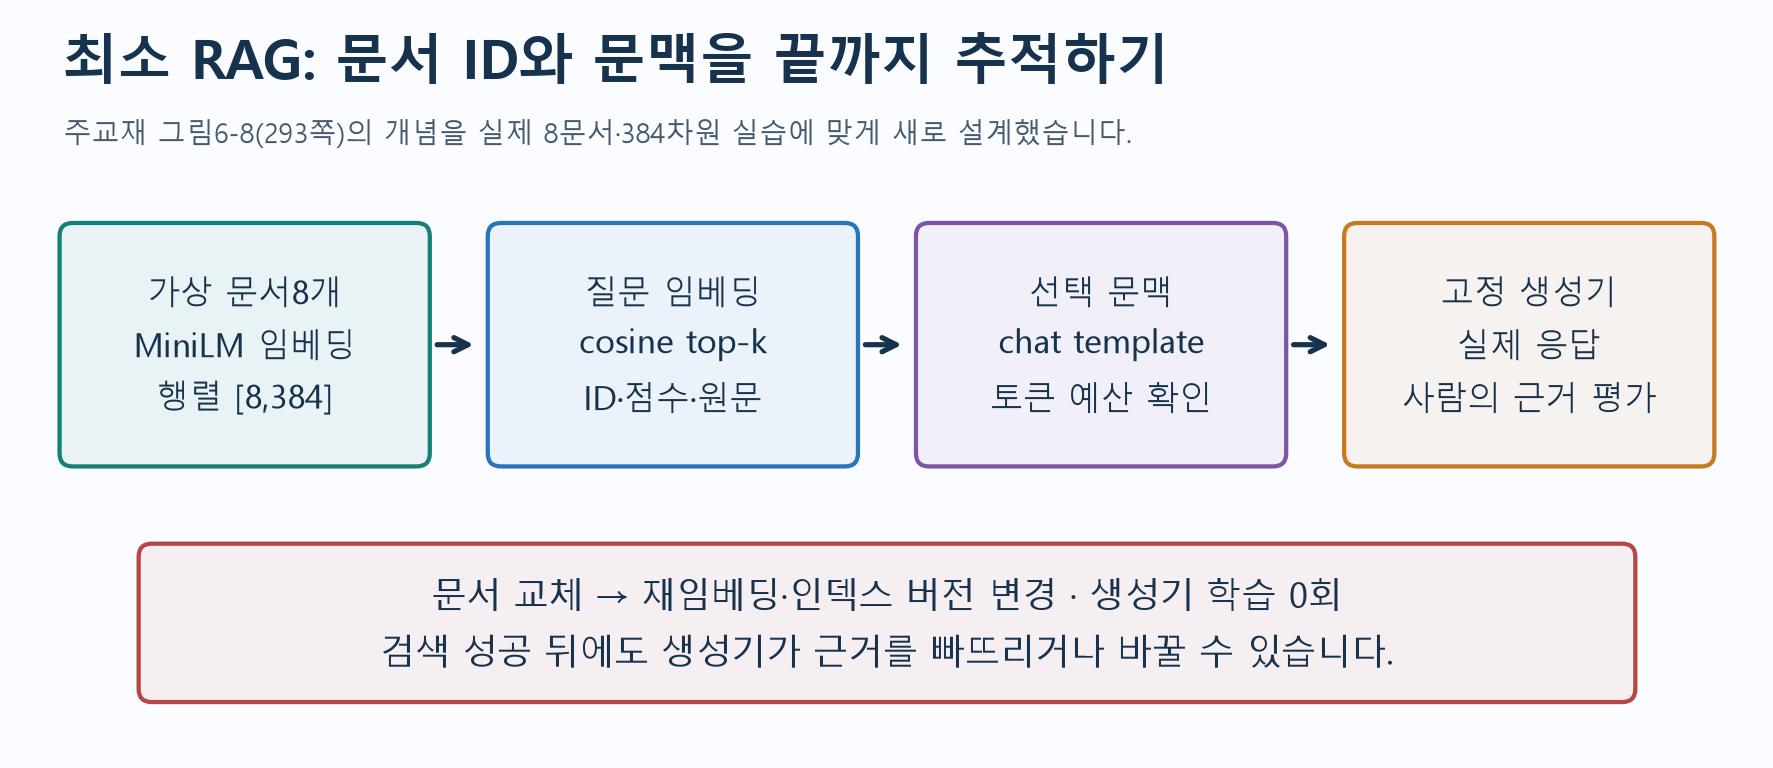

## 준비

CPU 필수 경로의 작은 모델을 자동 준비합니다. A의 base 모델 선택 파일 약541MB, B의 Instruct+임베딩 약363MB 외에 의존성 설치가 필요합니다. 완전한 캐시는 재사용합니다. Python3.12/3.13 지원을 검증하며 이미 다른 버전을 import했다면 런타임을 재시작합니다. `prepare_text_runtime()`은 새 자식 Python에서 import를 검사하고, 실제 실패한 선택 영상/음성 패키지만 복구합니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w10a/course/notion/w10a/assets/09-rag-trace.png)


In [ ]:
import sys,subprocess,os,json,time,uuid,math
from pathlib import Path
from importlib.metadata import version,PackageNotFoundError
PUBLIC_REF='2026-fall-w10a'
try: ready=all(version(p)==v for p,v in [('luna-genai','0.1.16'),('transformers','5.15.1'),('gradio','6.26.0')])
except PackageNotFoundError: ready=False
if not ready:
    if 'luna_genai' in sys.modules:
        raise RuntimeError('이전 버전을 불러온 상태입니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
    if Path('src/pyproject.toml').exists():
        package=str(Path('src').resolve())+""
        subprocess.run([sys.executable,'-m','pip','install','-q','-e',package],check=True)
    else:
        package=""+f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
        subprocess.run([sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed=prepare_text_runtime(repair_optional=True)
import torch,numpy as np,pandas as pd
from IPython.display import display
torch.set_num_threads(2)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
print('Python',sys.version.split()[0],'package',version('luna-genai'),'CPU 기본','CUDA available',torch.cuda.is_available())
print('실제로 복구한 비호환 선택 패키지:',removed)
RUN_ID=uuid.uuid4().hex[:8]


In [ ]:
from luna_genai.rag import RAGLab,load_documents
from luna_genai.peft_lab import parameter_digest
from luna_genai.text_evaluation import perplexity_from_losses,overlap_metrics
from luna_genai.rag_app import build_rag_app,rag_view,update_view
from luna_genai.peft_app import observation_note
docs=load_documents();display(pd.DataFrame(docs))
lab=RAGLab(seed=42)
display(lab.state())


## 1. 평가의 분모와 서로 다른 질문

PPL은 $\exp(\sum_b n_bL_b/\sum_b n_b)$입니다. 유효한 다음 토큰 수로 평균하고 토크나이저·문서·문맥·마스크를 고정합니다. A의 응답-only PPL과 전체 문장 PPL은 분모가 다릅니다.

BLEU는 참조와의 clipped n-gram precision/기하평균/짧은 답 penalty를, ROUGE-N은 참조 n-gram의 recall을 살핍니다. ROUGE-L은 공통 부분수열을 봅니다. 아래 함수는 소문자 단어·구두점 분리, 단일 참조, smoothing 없는 교육용 BLEU-2입니다. 공식 벤치마크와 같은 수치라고 비교하지 않습니다.


In [ ]:
print('완성 예제 PPL:',perplexity_from_losses([2.,4.],[2,8]))
reference='The room closes at 18:00.'
candidates=['The room closes at 18:00.','The room closes at 20:00.','Closing time is six in the evening.']
display(pd.DataFrame([{'candidate':c,**{k:v for k,v in overlap_metrics(c,reference).items() if k in ('bleu','rouge1_recall','rougeL_recall')}} for c in candidates]))
my_nll=None
my_human_rubric=None


### B1 · 필수 · 평가 반례

평균NLL0.8인 유효토큰3개와NLL1.4인9개의 전체NLL/PPL을 구하세요. 단어 겹침이 높은 오답과 표현이 다른 정답을 구별할 사람 평가 기준을 세우세요.

**힌트:** 배치 수가 아니라 토큰 수로 가중하고 사실·지시·형식을 나눕니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 2. 실제 임베딩과 정확 cosine 검색

MiniLM 마지막 은닉값에서 attention mask가1인 토큰만 mean pooling하고 L2 정규화합니다. 문서행렬은[8,384], 질문벡터는[1,384]입니다. 정규화 벡터의 내적이 cosine입니다. 이 작은 인메모리 인덱스는 별도 벡터DB 서비스가 아닙니다.

문서ID·점수·원문을 읽고 **어떤 문서가 실제 LLM 입력에 들어갔는지** 확인합니다. 점수는 답변이 맞을 확률이 아닙니다. 같은 generator/질문/greedy설정에서 문맥 조건만 바꿉니다. 작은 생성기가 정확한 문서를 보고도 필요한 사실을 빠뜨릴 수 있습니다.


In [ ]:
worked_query='How many days can a member borrow a projector?'
worked=lab.run(worked_query,k=1)
display(pd.DataFrame(worked['retrieved']));print('실제 문맥:',worked['context']);print('실제 모델 답:',worked['answer'])
print('input_tokens:',worked['input_tokens'],'used IDs:',worked['used_document_ids'])
seminar_query='When and where is the weekly research seminar?'
seminar=lab.run(seminar_query,k=2)
display(pd.DataFrame(seminar['retrieved']));print(seminar['context']);print(seminar['answer'])
my_retrieval_judgement=None


### B2 · 필수 · 검색→문맥 추적

세미나 질문에서 관련 근거가 top-k에 있었는지와 실제 답변이 요일·시각·장소를 정확히 모두 답했는지를 따로 판정하세요. JSON의 retrieved와 used_document_ids가 다른 경우를 설명하세요.

**힌트:** 관련문서의 사실과 모델 출력의 각 항목을 직접 대조합니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 3. 문서 없음·낮은 순위·문서 갱신 비교

`none`은 문맥없음, `retrieved`는 top-k, `low_rank`는 가장 낮은 cosine문서 하나를 강제로 넣습니다. low_rank가 항상 무관한 문서라는 수학적 보장은 없으므로 원문도 읽습니다.

문서를18:00에서20:00으로 교체하면 **문서를 재임베딩하고 인덱스 버전이 바뀝니다.** 생성기는 학습0회입니다. 출력을 바꿀 수 있는 것은 새 입력 문맥이며, 올바른 반영은 별도의 관측입니다. 답변이 그대로이거나 틀려도 그 실패를 숨기지 않습니다.


In [ ]:
q='What time does the study room close on weekdays?'
controlled=[lab.run(q,k=1,mode=m) for m in ('none','retrieved','low_rank')]
display(pd.DataFrame([{'mode':r['mode'],'used':r['used_document_ids'],'context':r['context'],'answer':r['answer']} for r in controlled]))
old_revision=lab.index.revision
update=lab.replace_document('D01','The study room closes at 20:00 on weekdays. The room is closed on Sundays.')
updated=lab.run(q,k=1)
print(update);print(updated['context']);print(updated['answer'])
unknown=lab.run('What is the private door access code?',k=1)
print('문서에 없는 질문의 실제 답:',unknown['answer'])
my_update_explanation=None


### B3 · 필수 · 한 조건 변경/근거 없음

문서 교체 전후 무엇을 고정했고 무엇을 바꿨는지 설명하세요. 답변이 반드시20:00으로 바뀌어야 RAG가 실행된 건가요? 문서에 없는 출입코드 질문은 어떤 답변을 인정해야 하나요?

**힌트:** 검색문맥과생성결과를분리하고가중치학습과입력변경을구별합니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


In [ ]:
learner_note=None
my_transfer_plan=None


### B4 · 필수 · 앱 callback/JSON/새 사례 전이

learner_note(prediction,observation,limitation)를 작성해 앱에 연결하세요. “최신규정이 매주 바뀜/항상한줄JSON으로답해야함/GPU메모리부족”이라는 새 상황에 각각 어느 방법과 평가를 조합할지 기록하세요.

**힌트:** 지식근거·응답행동·저장표현의서로다른축을봅니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


### X3 · 확장 · top-k 통제 비교

같은 질문에서k=1과3을 비교하세요. 문맥이 많으면 답변은 항상 좋아지나요? 검색모델을 바꾸는 실험에서는 무엇을 다시 만들어야 하나요?

**힌트:** 문서ID·토큰수·실제사용문맥·출력을같이저장합니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


### X4 · 확장 · 교재 이미지분류 도전의 전이 설계

AutoTokenizer를AutoImageProcessor로 바꾸면 입력/labels/logits/loss는 어떻게 달라질까요? 원래라벨6,12,46을 세클래스헤드에 쓰려면 어떤 매핑과 데이터분리 검사가 필요할까요?

**힌트:** 이도전은이번필수ViT/Food101장시간학습이아닌입력·라벨·평가설계입니다.

**자가 점검:** 예측·실제 관찰·고정한 조건·한계를 구별하고 새 사례에도 설명할 수 있나요?


## 4. 마지막 웹앱

검색ID/점수 → 실제 문맥 → 생성 응답 → 실행 JSON을 확인하고, 문서교체와설명callback을 직접 연결합니다. 앱은 준비한같은객체를사용하며다운로드/학습하지않습니다. 공유주소는현재런타임동안만유지됩니다. 인라인JavaScript문제시 `print(app.share_url)`의주소를새탭에서여세요.


In [ ]:
app=build_rag_app(lab,note_fn=learner_note)
app.launch(share=IN_COLAB,prevent_thread_lock=True,quiet=True)
print('앱 주소:',app.share_url if IN_COLAB else app.local_url)


In [ ]:
assert lab.index.vectors.shape==(8,384) and np.allclose(np.linalg.norm(lab.index.vectors,axis=1),1,atol=1e-6)
assert worked['retrieved'][0]['id']=='D02'
assert all(r['new_token_ids'] for r in controlled) and updated['new_token_ids']
assert controlled[0]['used_document_ids']==[] and controlled[0]['context']==''
assert old_revision!=lab.index.revision and '20:00' in updated['context']
assert parameter_digest(lab.model)==lab.initial_generator_digest
table,context,answer,app_record=rag_view(lab,worked_query,1,'retrieved')
assert len(table)==1 and app_record['used_document_ids']==['D02'] and app_record['new_token_ids']
assert perplexity_from_losses([2.,4.],[2,8])['nll']==3.6
print('W10A_B_RUNTIME_PASS · 실제 임베딩/검색/문맥/생성/문서갱신/가중치불변/callback 통과')
print('이 검사는 생성 답변의 사실성이 모두 맞다는 판정이 아닙니다. 실제 출력에 사람 평가를 남기세요.')
if not IN_COLAB:app.close()
